Đã đọc 3,751 điểm từ: /var/local/qe/projects/XRD_61028/raw/HE M2BDC MOF_Theta_2-Theta.txt
Đã lưu biểu đồ raw vào: /var/local/qe/projects/XRD_61028/processed/raw_pattern.png


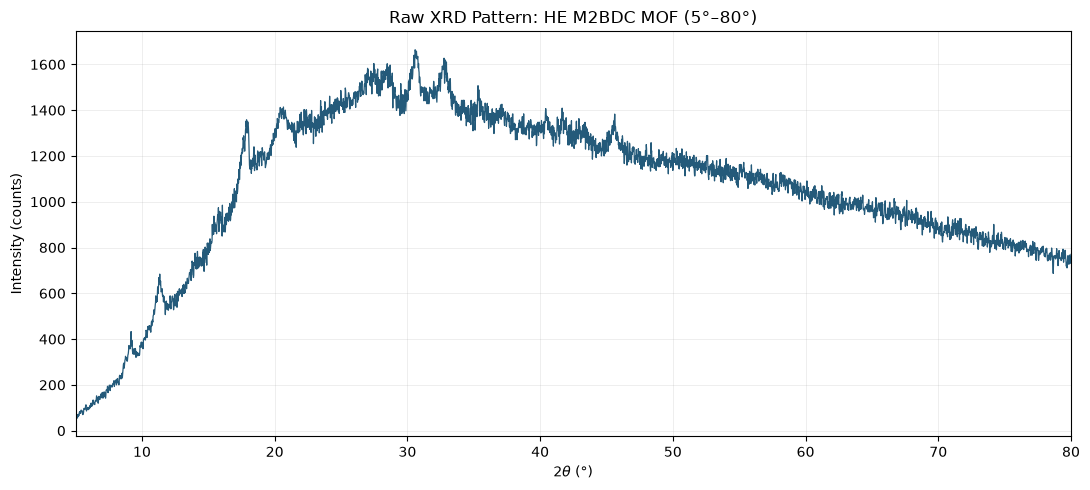

In [25]:
# Vẽ và lưu biểu đồ raw vào folder processed
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd

_here = Path.cwd().resolve()
search_roots = [_here, *_here.parents]
sample_dir = next(
    (
        candidate
        for root in search_roots
        for candidate in (root, root / "XRD_61028", root / "projects" / "XRD_61028")
        if (candidate / "raw").is_dir()
    ),
    None,
)
if sample_dir is None:
    raise FileNotFoundError("Không tìm thấy thư mục chứa 'raw/' cho mẫu XRD_61028")

# Chỉ định đích danh file dữ liệu 2-Theta (hoặc tự tìm file có đuôi _Theta_2-Theta.txt)
data_path = sample_dir / "raw/HE M2BDC MOF_Theta_2-Theta.txt"
if not data_path.is_file():
    theta_files = sorted((sample_dir / "raw").glob("*Theta_2-Theta*.txt"))
    if not theta_files:
        raise FileNotFoundError(f"Không tìm thấy file *Theta_2-Theta*.txt trong {sample_dir / 'raw'}")
    data_path = theta_files[0]

output_dir = sample_dir / "processed"
output_dir.mkdir(parents=True, exist_ok=True)
theta_min, theta_max = 5.0, 80.0

# Đọc dữ liệu, ép kiểu số và tự động loại bỏ các dòng chữ mô tả/header nếu có
xrd = pd.read_csv(
    data_path,
    sep=r"\s+",
    comment="#",
    header=None,
    usecols=[0, 1],
    names=["two_theta", "intensity"],
    on_bad_lines="skip",
)
xrd["two_theta"] = pd.to_numeric(xrd["two_theta"], errors="coerce")
xrd["intensity"] = pd.to_numeric(xrd["intensity"], errors="coerce")
xrd = xrd.dropna().sort_values("two_theta").reset_index(drop=True)

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(xrd["two_theta"], xrd["intensity"], color="#245a7a", linewidth=0.9)
ax.set(
    title=f"Raw XRD Pattern: HE M2BDC MOF ({theta_min:g}°–{theta_max:g}°)",
    xlabel=r"$2\theta$ (°)",
    ylabel="Intensity (counts)",
    xlim=(theta_min, theta_max),
)
ax.grid(True, alpha=0.25, linewidth=0.6)
fig.tight_layout()

raw_plot_path = output_dir / "raw_pattern.png"
fig.savefig(raw_plot_path, dpi=300, bbox_inches="tight")
print(f"Đã đọc {len(xrd):,} điểm từ: {data_path}")
print(f"Đã lưu biểu đồ raw vào: {raw_plot_path}")
plt.show()

Đã cắt phổ XRD từ 5° đến 50°. Số điểm hiện tại: 2,251


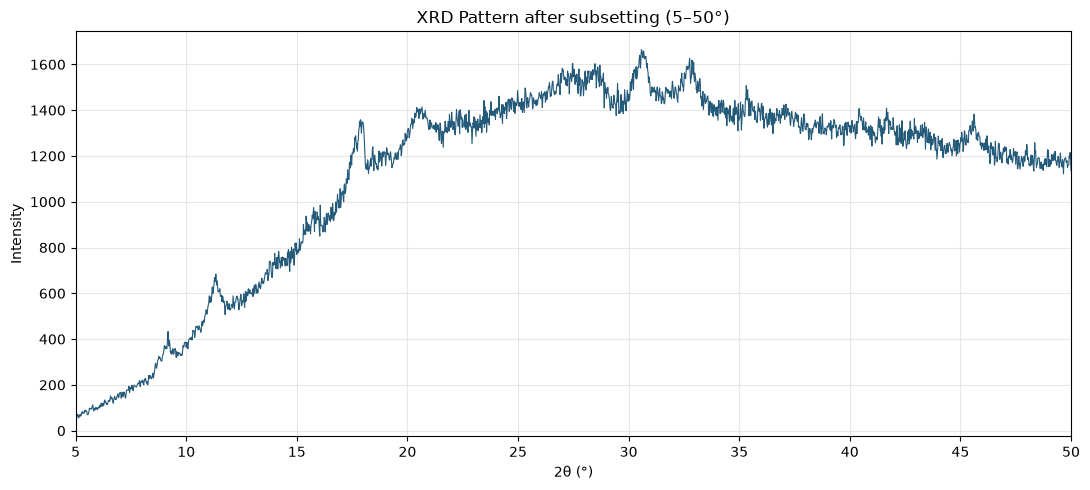

In [26]:
# Chọn khoảng 2θ dùng cho các bước xử lý tiếp theo (điều chỉnh tại đây)
process_theta_min = 5.0
process_theta_max = 50.0

# Cắt phổ theo khoảng đã chọn
xrd = xrd[xrd["two_theta"].between(process_theta_min, process_theta_max)].copy().reset_index(drop=True)
if xrd.empty:
    raise ValueError(
        f"Không có dữ liệu trong khoảng {process_theta_min:g}°–{process_theta_max:g}°. "
        "Kiểm tra lại giới hạn xử lý."
    )
print(
    f"Đã cắt phổ XRD từ {process_theta_min:g}° đến {process_theta_max:g}°. "
    f"Số điểm hiện tại: {len(xrd):,}"
)

# Kiểm tra hình ảnh sau khi cắt
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(xrd["two_theta"], xrd["intensity"], color="#245a7a", linewidth=0.8)
ax.set(
    title=f"XRD Pattern after subsetting ({process_theta_min:g}–{process_theta_max:g}°)",
    xlabel="2θ (°)",
    ylabel="Intensity",
    xlim=(process_theta_min, process_theta_max),
)
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

Baseline fit: smoothing=1e+06, asymmetry=0.001, points=2,251


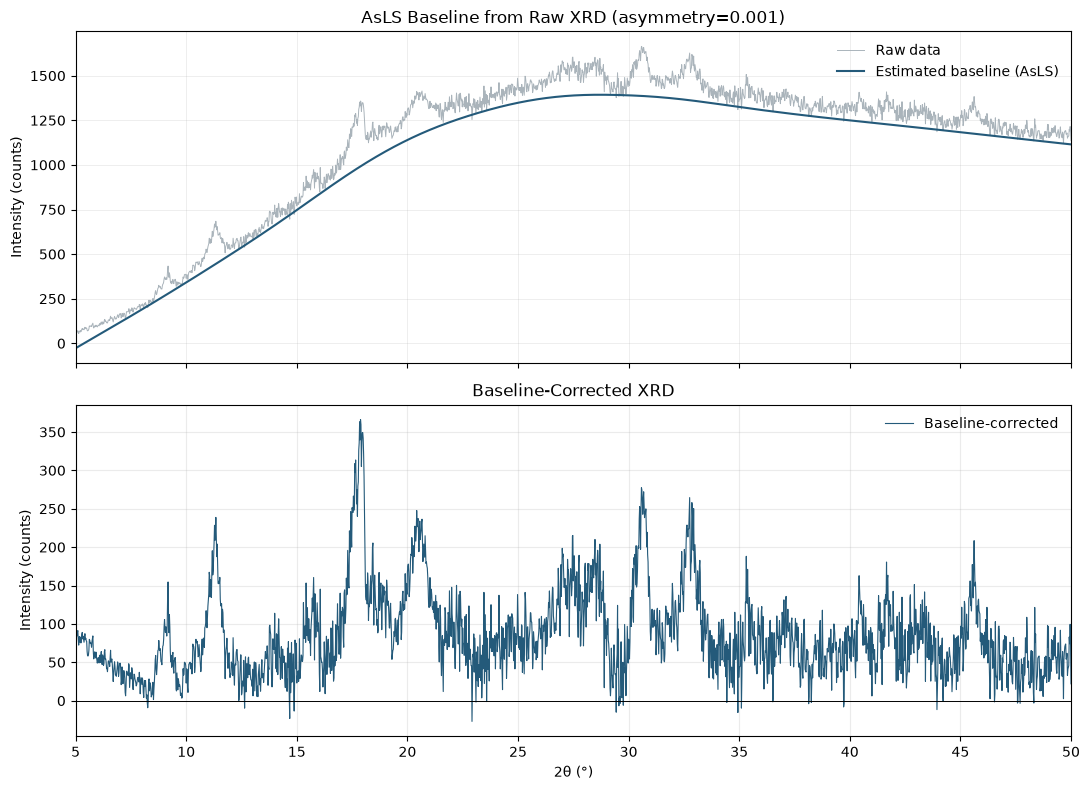

Đã gán phổ sau trừ nền vào corrected_intensity.


In [27]:
import numpy as np
from scipy import sparse
from scipy.sparse.linalg import spsolve

# --- Tham số cho việc tách nền ---
smoothing = 1e6
asymmetry = 0.001


def estimate_asls_baseline(intensity, smoothing=1e6, asymmetry=0.001, iterations=10):
    """Ước lượng đường nền bằng thuật toán Asymmetric Least Squares (AsLS)."""
    values = np.asarray(intensity, dtype=float)
    point_count = values.size
    difference = sparse.diags(
        [np.ones(point_count - 2), -2 * np.ones(point_count - 2), np.ones(point_count - 2)],
        [0, 1, 2],
        shape=(point_count - 2, point_count),
        format="csc",
    )
    penalty = smoothing * (difference.T @ difference)
    weights = np.ones(point_count)

    for _ in range(iterations):
        weight_matrix = sparse.diags(weights, format="csc")
        baseline = spsolve(weight_matrix + penalty, weights * values)
        weights = np.where(values > baseline, asymmetry, 1 - asymmetry)

    return baseline


# --- Thực hiện tính toán đường nền ---
xrd["baseline"] = estimate_asls_baseline(
    xrd["intensity"],
    smoothing=smoothing,
    asymmetry=asymmetry,
)
xrd["baseline_corrected"] = xrd["intensity"] - xrd["baseline"]
print(f"Baseline fit: smoothing={smoothing:g}, asymmetry={asymmetry:g}, points={len(xrd):,}")

# --- Trực quan hóa gộp 2 tầng chung trục 2θ ---
fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True)

# Tầng 1: Phổ gốc và đường nền AsLS
axes[0].plot(xrd["two_theta"], xrd["intensity"], color="#aab4bb", linewidth=0.7, label="Raw data")
axes[0].plot(xrd["two_theta"], xrd["baseline"], color="#245a7a", linewidth=1.5, label="Estimated baseline (AsLS)")
axes[0].set(
    title=f"AsLS Baseline from Raw XRD (asymmetry={asymmetry:g})",
    ylabel="Intensity (counts)",
)
axes[0].grid(True, alpha=0.25, linewidth=0.6)
axes[0].legend(frameon=False)

# Tầng 2: Phổ sau trừ nền
axes[1].plot(
    xrd["two_theta"],
    xrd["baseline_corrected"],
    color="#245a7a",
    linewidth=0.8,
    label="Baseline-corrected",
)
axes[1].axhline(0, color="black", linewidth=0.7)
axes[1].set(
    title="Baseline-Corrected XRD",
    xlabel="2θ (°)",
    ylabel="Intensity (counts)",
    xlim=(process_theta_min, process_theta_max),
)
axes[1].grid(True, alpha=0.25)
axes[1].legend(frameon=False)

fig.tight_layout()
plt.show()

# --- Gán kết quả ---
# Không dịch phổ theo cường độ: giữ nguyên kết quả trừ nền.
xrd["corrected_intensity"] = xrd["baseline_corrected"]
print("Đã gán phổ sau trừ nền vào corrected_intensity.")

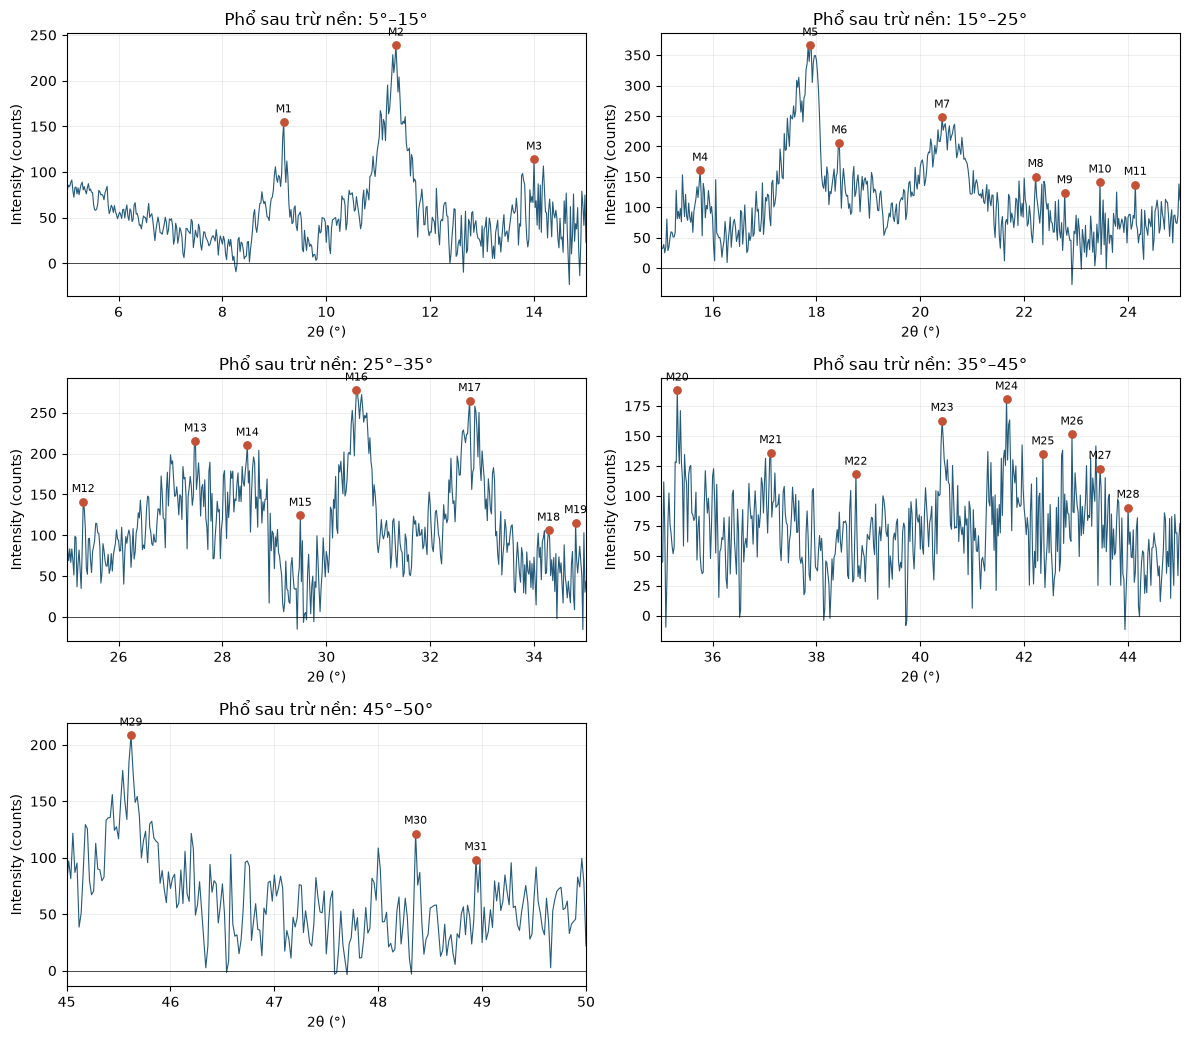

Đã đánh số 31 peak; prominence tối thiểu = 90.8 counts


In [28]:
# --- Xem phổ sau trừ nền theo từng đoạn và đánh số peak ---
from scipy.signal import find_peaks

segment_width = 10.0  # độ rộng mỗi đoạn theo 2θ (°); có thể thay đổi
segment_edges = list(np.arange(process_theta_min, process_theta_max, segment_width))
if not segment_edges or segment_edges[0] != process_theta_min:
    segment_edges.insert(0, process_theta_min)
segment_edges.append(process_theta_max)
segment_count = len(segment_edges) - 1
segment_columns = 2
segment_rows = int(np.ceil(segment_count / segment_columns))

# Dùng tiêu chí phát hiện peak cùng kiểu với cell so sánh phía dưới.
sampling_step = float(xrd["two_theta"].diff().median())
corrected_signal = xrd["corrected_intensity"].to_numpy(dtype=float)
second_difference = np.diff(corrected_signal, n=2)
noise_sigma = float(
    np.median(np.abs(second_difference - np.median(second_difference)))
    / (0.6745 * np.sqrt(6))
)
# Cùng ngưỡng và khoảng cách với phần tìm peak rõ ở cell so sánh phía dưới.
segment_peak_prominence = max(6 * noise_sigma, 0.06 * np.ptp(corrected_signal))
segment_peak_distance = max(1, int(round(0.50 / sampling_step)))

fig, axes = plt.subplots(
    segment_rows, segment_columns,
    figsize=(12, 3.5 * segment_rows),
    squeeze=False,
    sharey=False,
)
peak_number = 1
for segment_index, ax in enumerate(axes.flat):
    if segment_index >= segment_count:
        ax.set_visible(False)
        continue
    left, right = segment_edges[segment_index:segment_index + 2]
    segment = xrd[xrd["two_theta"].between(left, right, inclusive="both")]
    segment_signal = segment["corrected_intensity"].to_numpy(dtype=float)
    segment_angles = segment["two_theta"].to_numpy(dtype=float)
    peak_indices, _ = find_peaks(
        segment_signal,
        prominence=segment_peak_prominence,
        distance=segment_peak_distance,
    )

    ax.plot(segment_angles, segment_signal, color="#245a7a", linewidth=0.8)
    ax.axhline(0, color="black", linewidth=0.7, alpha=0.7)
    if len(peak_indices):
        ax.scatter(segment_angles[peak_indices], segment_signal[peak_indices], color="#c45135", s=28, zorder=3)
        for peak_index in peak_indices:
            ax.annotate(
                f"M{peak_number}",
                (segment_angles[peak_index], segment_signal[peak_index]),
                xytext=(0, 7),
                textcoords="offset points",
                ha="center",
                fontsize=8,
            )
            peak_number += 1
    ax.set(
        title=f"Phổ sau trừ nền: {left:g}°–{right:g}°",
        xlabel="2θ (°)",
        ylabel="Intensity (counts)",
        xlim=(left, right),
    )
    ax.grid(True, alpha=0.25, linewidth=0.6)
fig.tight_layout()
plt.show()
print(f"Đã đánh số {peak_number - 1} peak; prominence tối thiểu = {segment_peak_prominence:.1f} counts")

Protected 11 prominent peaks (prominence >= 151.3 counts)
Selected 25 points (polyorder=3, 0.48°): best available window; at least one peak check did not pass
Protected peaks retained: 4/11
Peak near 18°: 17.88°, preserved


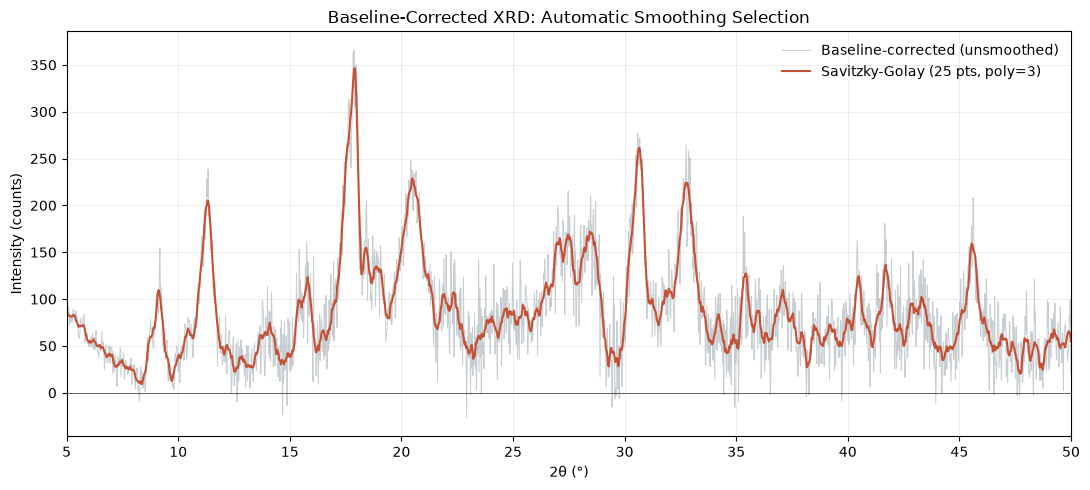

In [29]:
from scipy.signal import find_peaks, savgol_filter

angle = xrd["two_theta"].to_numpy(dtype=float)
signal = xrd["corrected_intensity"].to_numpy(dtype=float)
sampling_step = float(xrd["two_theta"].diff().median())

# Tăng polyorder lên 3 để giữ chiều cao peak tốt hơn khi dùng cửa sổ rộng
polyorder = 3
candidate_windows = list(range(21, 47, 4))  # Thử từ 21 đến 45 điểm (~0.40° - 0.88°)
max_peak_shift = 0.06
minimum_prominence_retention = 0.65  # Cho phép triệt bỏ gai nhiễu nhọn trên chóp đỉnh
minimum_other_peak_fraction = 0.80

second_difference = np.diff(signal, n=2)
noise_sigma = float(np.median(np.abs(second_difference - np.median(second_difference))) / (0.6745 * np.sqrt(6)))
prominence_threshold = 10 * noise_sigma
minimum_peak_distance = max(1, int(round(0.20 / sampling_step)))

reference_peaks, reference_properties = find_peaks(
    signal,
    prominence=prominence_threshold,
    distance=minimum_peak_distance,
)
reference_prominences = reference_properties["prominences"]
protected_order = np.argsort(reference_prominences)[::-1][:12]
reference_peaks = reference_peaks[protected_order]
reference_prominences = reference_prominences[protected_order]

focus_candidates = np.flatnonzero(np.abs(angle[reference_peaks] - 18.0) <= 0.5)
focus_peak_index = (
    focus_candidates[np.argmin(np.abs(angle[reference_peaks[focus_candidates]] - 18.0))]
    if focus_candidates.size
    else None
)

candidate_results = []
for window_length in candidate_windows:
    smoothed = savgol_filter(signal, window_length=window_length, polyorder=polyorder)
    smooth_peaks, smooth_properties = find_peaks(
        smoothed,
        prominence=prominence_threshold * 0.5,
        distance=minimum_peak_distance,
    )
    smooth_prominences = smooth_properties["prominences"]
    peak_passes = np.zeros(len(reference_peaks), dtype=bool)
    peak_shifts = np.full(len(reference_peaks), np.nan)
    prominence_retentions = np.full(len(reference_peaks), np.nan)

    for peak_number, (reference_peak, reference_prominence) in enumerate(
        zip(reference_peaks, reference_prominences)
    ):
        nearby = np.flatnonzero(np.abs(angle[smooth_peaks] - angle[reference_peak]) <= max_peak_shift)
        if nearby.size == 0:
            continue

        matched_position = nearby[np.argmin(np.abs(angle[smooth_peaks[nearby]] - angle[reference_peak]))]
        peak_shifts[peak_number] = abs(angle[smooth_peaks[matched_position]] - angle[reference_peak])
        prominence_retentions[peak_number] = smooth_prominences[matched_position] / reference_prominence
        peak_passes[peak_number] = prominence_retentions[peak_number] >= minimum_prominence_retention

    focus_passes = focus_peak_index is None or peak_passes[focus_peak_index]
    other_peak_passes = peak_passes.copy()
    if focus_peak_index is not None:
        other_peak_passes[focus_peak_index] = True
    other_peak_fraction = float(other_peak_passes.mean()) if len(other_peak_passes) else 1.0
    candidate_results.append(
        {
            "window": window_length,
            "smoothed": smoothed,
            "peak_passes": peak_passes,
            "peak_shifts": peak_shifts,
            "prominence_retentions": prominence_retentions,
            "focus_passes": focus_passes,
            "other_peak_fraction": other_peak_fraction,
        }
    )

valid_candidates = [
    result
    for result in candidate_results
    if result["focus_passes"] and result["other_peak_fraction"] >= minimum_other_peak_fraction
]
if valid_candidates:
    selected = valid_candidates[-1]
    selection_status = "largest window meeting peak-preservation checks"
else:
    selected = max(
        candidate_results,
        key=lambda result: (
            result["focus_passes"],
            int(result["peak_passes"].sum()),
            -result["window"],
        ),
    )
    selection_status = "best available window; at least one peak check did not pass"

selected_window = selected["window"]
xrd["smoothed_auto"] = selected["smoothed"]
window_span = (selected_window - 1) * sampling_step
print(f"Protected {len(reference_peaks)} prominent peaks (prominence >= {prominence_threshold:.1f} counts)")
print(f"Selected {selected_window} points (polyorder={polyorder}, {window_span:.2f}°): {selection_status}")
print(f"Protected peaks retained: {int(selected['peak_passes'].sum())}/{len(reference_peaks)}")
if focus_peak_index is not None:
    print(
        f"Peak near 18°: {angle[reference_peaks[focus_peak_index]]:.2f}°, "
        f"{'preserved' if selected['focus_passes'] else 'check manually'}"
    )

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(
    angle,
    signal,
    color="#aab4bb",
    linewidth=0.7,
    alpha=0.65,
    label="Baseline-corrected (unsmoothed)",
)
ax.plot(
    angle,
    xrd["smoothed_auto"],
    color="#c45135",
    linewidth=1.5,
    label=f"Savitzky-Golay ({selected_window} pts, poly={polyorder})",
)
ax.axhline(0, color="black", linewidth=0.7, alpha=0.6)
ax.set(
    title="Baseline-Corrected XRD: Automatic Smoothing Selection",
    xlabel="2θ (°)",
    ylabel="Intensity (counts)",
    xlim=(process_theta_min, process_theta_max),  # Khớp đúng vùng 5°-50°
)
ax.grid(True, alpha=0.25, linewidth=0.6)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

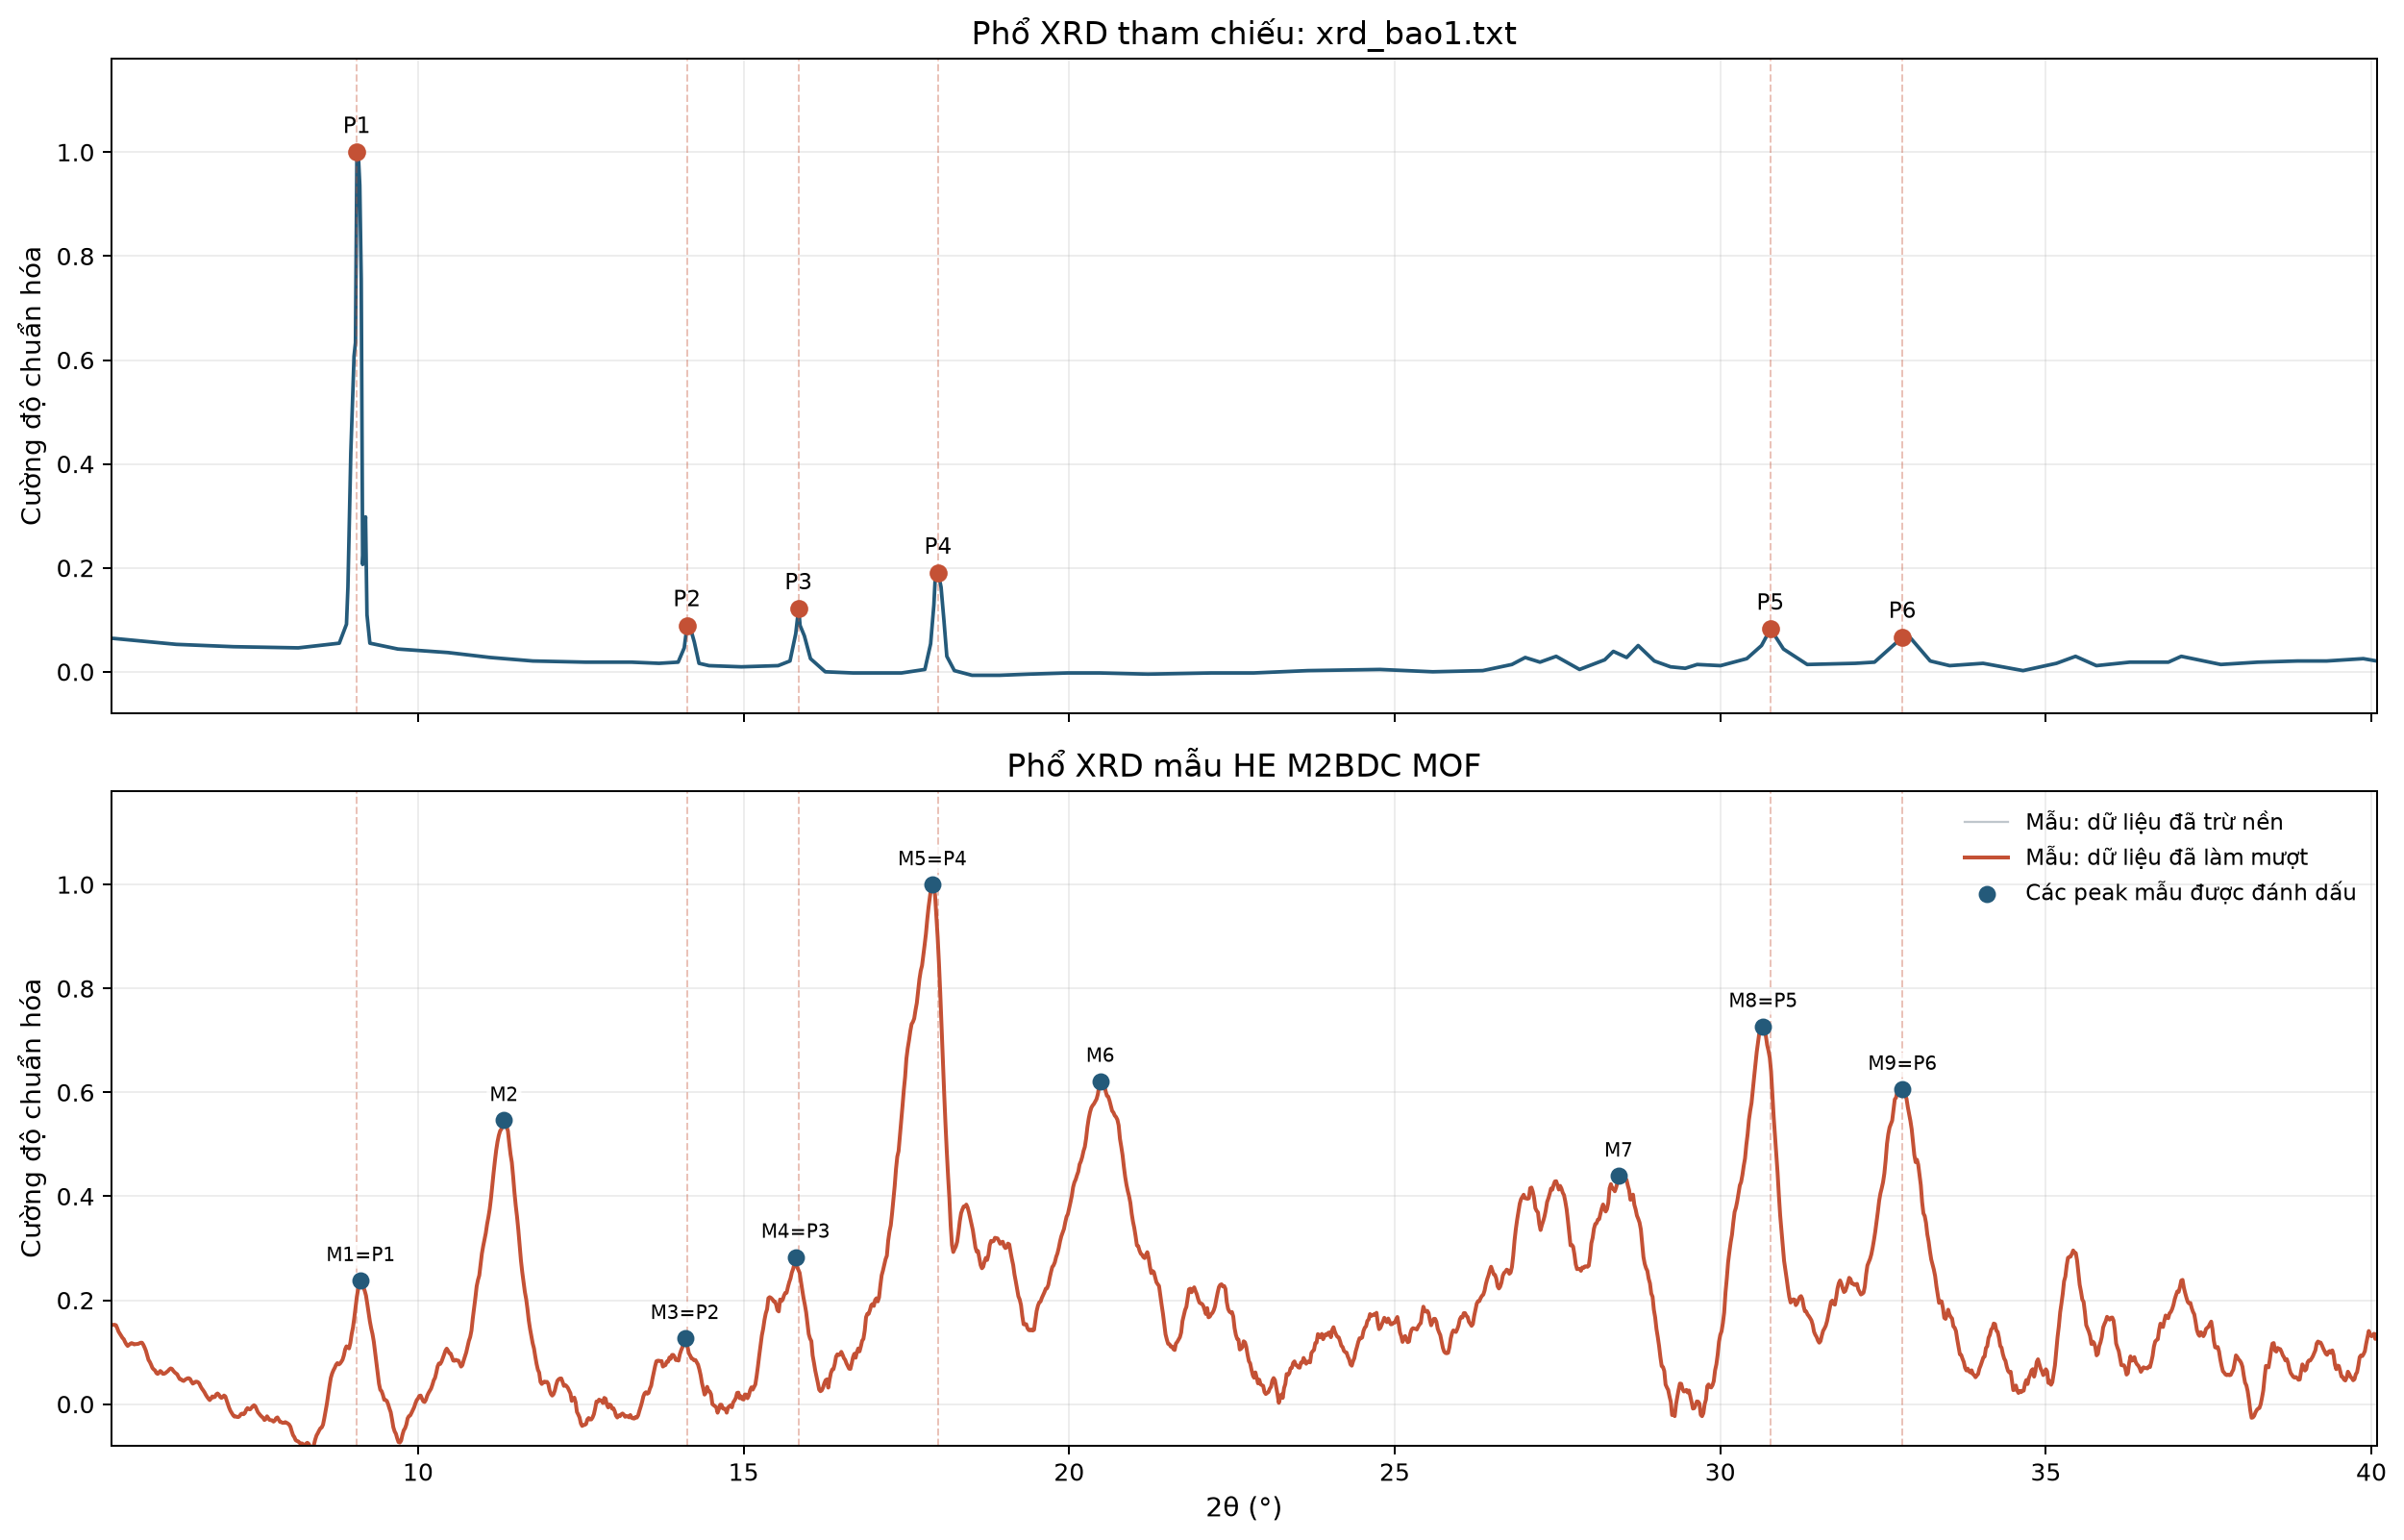

Đã lưu hình độ phân giải cao: /var/local/qe/projects/XRD_61028/xrd_bao1_comparison.png
Khoảng 2θ chung được so sánh: 5.29°–40.08°


,Đỉnh bài báo,2θ bài báo (°),2θ mẫu (°),Độ lệch Δ2θ (°),Kết quả đối chiếu
0,P1,9.061,9.12,0.059,Đỉnh gần nhất
1,P2,14.132,14.10,-0.032,Đỉnh gần nhất
2,P3,15.845,15.80,-0.045,Đỉnh gần nhất
3,P4,17.988,17.90,-0.088,Đỉnh gần nhất
4,P5,30.772,30.66,-0.112,Đỉnh gần nhất
5,P6,32.799,32.80,0.001,Đỉnh gần nhất


Số peak rõ của mẫu: 9; số peak khớp bài báo: 6/6


,Đỉnh mẫu,2θ mẫu (°),Cường độ sau trừ nền,Độ nổi bật,Đỉnh bài báo,2θ bài báo (°),Độ lệch Δ2θ (°),Kết quả đối chiếu
0,M1,9.12,109.536,97.045,P1,9.061,0.059,Khớp với bài báo
1,M2,11.32,205.302,182.894,,NaN,NaN,"Peak rõ, chưa thấy trong bài báo"
2,M3,14.10,74.889,44.567,P2,14.132,-0.032,Khớp với bài báo
3,M4,15.80,123.484,80.306,P3,15.845,-0.045,Khớp với bài báo
4,M5,17.90,346.333,319.050,P4,17.988,-0.088,Khớp với bài báo
5,M6,20.48,228.746,149.257,,NaN,NaN,"Peak rõ, chưa thấy trong bài báo"
6,M7,28.44,172.048,135.846,,NaN,NaN,"Peak rõ, chưa thấy trong bài báo"
7,M8,30.66,261.480,233.241,P5,30.772,-0.112,Khớp với bài báo
8,M9,32.80,223.973,151.766,P6,32.799,0.001,Khớp với bài báo


In [30]:
from scipy.optimize import linear_sum_assignment
from scipy.signal import find_peaks
from IPython.display import display

paper_filename = "xrd_bao1.txt"
paper_path = next(
    (
        candidate
        for root in search_roots
        for candidate in (
            sample_dir / "raw" / paper_filename,
            sample_dir / "PAPER" / paper_filename,
            root / "PAPER" / paper_filename,
            root / "projects" / "PAPER" / paper_filename,
        )
        if candidate.is_file()
    ),
    None,
)
if paper_path is None:
    raise FileNotFoundError(f"Không tìm thấy file phổ tham chiếu: {paper_filename}")

paper = pd.read_csv(paper_path, sep=r"\s+", header=None, names=["two_theta", "intensity"])
paper = paper.groupby("two_theta", as_index=False)["intensity"].mean().sort_values("two_theta").reset_index(drop=True)

comparison_min = max(theta_min, paper["two_theta"].min())
comparison_max = min(theta_max, paper["two_theta"].max())
paper = paper.loc[paper["two_theta"].between(comparison_min, comparison_max)].reset_index(drop=True)
ours = xrd.loc[xrd["two_theta"].between(comparison_min, comparison_max)].copy().reset_index(drop=True)

raw_paper_peak_indices, raw_paper_properties = find_peaks(paper["intensity"].to_numpy(), prominence=2.5, distance=2)
raw_paper_order = np.argsort(paper.loc[raw_paper_peak_indices, "two_theta"].to_numpy())
raw_paper_peak_indices = raw_paper_peak_indices[raw_paper_order]
raw_paper_prominences = raw_paper_properties["prominences"][raw_paper_order]

peak_clusters = []
for peak_index in raw_paper_peak_indices:
    peak_angle = float(paper.loc[peak_index, "two_theta"])
    if not peak_clusters or peak_angle - float(paper.loc[peak_clusters[-1][-1], "two_theta"]) > 0.30:
        peak_clusters.append([peak_index])
    else:
        peak_clusters[-1].append(peak_index)

paper_peak_indices = []
paper_peak_prominences = []
for cluster in peak_clusters:
    cluster_angles = paper.loc[cluster, "two_theta"]
    cluster_rows = paper.index[paper["two_theta"].between(cluster_angles.min(), cluster_angles.max())]
    paper_peak_indices.append(int(paper.loc[cluster_rows, "intensity"].idxmax()))
    paper_peak_prominences.append(float(max(raw_paper_prominences[np.isin(raw_paper_peak_indices, cluster)])))
paper_peak_prominences = np.asarray(paper_peak_prominences)

# Đồng nhất sử dụng tín hiệu sau trừ nền
ours_signal = ours["smoothed_auto"].to_numpy(dtype=float)
own_peak_indices, own_peak_properties = find_peaks(
    ours_signal,
    prominence=max(15.0, 0.04 * np.ptp(ours_signal)),
    distance=max(1, int(round(0.35 / sampling_step))),
)
match_tolerance = 0.6
paper_angles = paper.loc[paper_peak_indices, "two_theta"].to_numpy(dtype=float)
own_angles = ours.loc[own_peak_indices, "two_theta"].to_numpy(dtype=float)
distance_matrix = np.abs(paper_angles[:, None] - own_angles[None, :])

if len(paper_angles) and len(own_angles):
    unmatched_cost = match_tolerance + 1e-9
    invalid_cost = unmatched_cost * (len(paper_angles) + len(own_angles) + 1)
    cost_matrix = np.full((len(paper_angles), len(own_angles) + len(paper_angles)), unmatched_cost)
    cost_matrix[:, :len(own_angles)] = np.where(
        distance_matrix <= match_tolerance,
        distance_matrix,
        invalid_cost,
    )
    paper_assignment, own_assignment = linear_sum_assignment(cost_matrix)
    matched_own_by_paper = {
        int(paper_row): int(own_peak_indices[own_col])
        for paper_row, own_col in zip(paper_assignment, own_assignment)
        if own_col < len(own_angles) and distance_matrix[paper_row, own_col] <= match_tolerance
    }
else:
    matched_own_by_paper = {}

peak_rows = []
for peak_number, (paper_index, paper_prominence) in enumerate(zip(paper_peak_indices, paper_peak_prominences), start=1):
    paper_angle = float(paper.loc[paper_index, "two_theta"])
    own_index = matched_own_by_paper.get(peak_number - 1)
    own_angle = float(ours.loc[own_index, "two_theta"]) if own_index is not None else np.nan
    peak_rows.append(
        {
            "Peak": f"P{peak_number}",
            "paper_index": paper_index,
            "our_index": int(own_index) if own_index is not None else None,
            "Paper 2θ (°)": paper_angle,
            "Our 2θ (°)": own_angle,
            "Δ2θ (°)": own_angle - paper_angle if own_index is not None else np.nan,
            "Match": "Matched one-to-one" if own_index is not None else f"No detected peak within ±{match_tolerance:.1f}°",
            "Paper prominence": paper_prominence,
        }
    )

matches = pd.DataFrame(peak_rows)
matched_rows = [row for row in peak_rows if row["our_index"] is not None]
matched_own_indices = {int(row["our_index"]) for row in matched_rows}
match_by_our_index = {int(row["our_index"]): row for row in matched_rows}

clear_signal = ours["smoothed_auto"].to_numpy(dtype=float)
clear_peak_threshold = max(6 * noise_sigma, 0.06 * np.ptp(clear_signal))
clear_peak_indices, clear_peak_properties = find_peaks(
    clear_signal,
    prominence=clear_peak_threshold,
    distance=max(1, int(round(0.50 / sampling_step))),
)
clear_prominence_by_index = {int(index): float(value) for index, value in zip(clear_peak_indices, clear_peak_properties["prominences"])}
raw_prominence_by_index = {int(index): float(value) for index, value in zip(own_peak_indices, own_peak_properties["prominences"])}

# Tối ưu hóa truy xuất góc bằng mảng NumPy trực tiếp (vectorization, loại bỏ lặp qua pandas .loc)
ours_angles = ours["two_theta"].to_numpy(dtype=float)
matched_angles_array = ours_angles[list(matched_own_indices)] if matched_own_indices else np.array([])

unmatched_clear_indices = [
    int(index)
    for index in clear_peak_indices
    if len(matched_angles_array) == 0 or np.all(np.abs(ours_angles[index] - matched_angles_array) > 0.15)
]
unmatched_clear_indices.sort(key=lambda index: clear_prominence_by_index[index], reverse=True)

kept_unmatched_indices = []
for index in unmatched_clear_indices:
    if not kept_unmatched_indices or np.all(np.abs(ours_angles[index] - ours_angles[kept_unmatched_indices]) > 0.15):
        kept_unmatched_indices.append(index)

all_own_indices = sorted(
    matched_own_indices | set(kept_unmatched_indices),
    key=lambda index: ours_angles[index],
)

paper_floor = np.quantile(paper["intensity"], 0.10)
paper_scale = paper["intensity"].max() - paper_floor
paper_normalized = (paper["intensity"].to_numpy() - paper_floor) / paper_scale

ours_floor = np.quantile(ours_signal, 0.10)
ours_scale = ours_signal.max() - ours_floor
ours_normalized = (ours_signal - ours_floor) / ours_scale

ours_smoothed = ours["smoothed_auto"].to_numpy(dtype=float)
smooth_floor = np.quantile(ours_smoothed, 0.10)
smooth_scale = ours_smoothed.max() - smooth_floor
smooth_normalized = (ours_smoothed - smooth_floor) / smooth_scale

fig, axes = plt.subplots(2, 1, figsize=(14, 9), dpi=180, sharex=True)
axes[0].plot(paper["two_theta"], paper_normalized, color="#245a7a", linewidth=1.5)
axes[0].scatter(paper.loc[paper_peak_indices, "two_theta"], paper_normalized[paper_peak_indices], color="#c45135", s=42, zorder=3)
axes[0].set_ylabel("Cường độ chuẩn hóa", fontsize=11)
axes[0].set_title("Phổ XRD tham chiếu: xrd_bao1.txt", fontsize=13)

axes[1].plot(ours["two_theta"], ours_normalized, color="#aab4bb", linewidth=0.9, alpha=0.75, label="Mẫu: dữ liệu đã trừ nền")
axes[1].plot(ours["two_theta"], smooth_normalized, color="#c45135", linewidth=1.6, label="Mẫu: dữ liệu đã làm mượt")
axes[1].scatter(
    ours.loc[all_own_indices, "two_theta"],
    smooth_normalized[all_own_indices],
    color="#245a7a",
    s=38,
    zorder=3,
    label="Các peak mẫu được đánh dấu",
)
axes[1].set_ylabel("Cường độ chuẩn hóa", fontsize=11)
axes[1].set_xlabel("2θ (°)", fontsize=11)
axes[1].set_title("Phổ XRD mẫu HE M2BDC MOF", fontsize=13)
axes[1].legend(frameon=False, fontsize=9)

for peak_number, peak_index in enumerate(paper_peak_indices, start=1):
    peak_angle = float(paper.loc[peak_index, "two_theta"])
    axes[0].annotate(f"P{peak_number}", (peak_angle, paper_normalized[peak_index]), xytext=(0, 8), textcoords="offset points", ha="center", fontsize=9)
    for ax in axes:
        ax.axvline(peak_angle, color="#c45135", linestyle="--", linewidth=0.8, alpha=0.35)

for peak_number, own_index in enumerate(all_own_indices, start=1):
    reference_match = match_by_our_index.get(own_index)
    peak_label = f"M{peak_number}={reference_match['Peak']}" if reference_match else f"M{peak_number}"
    axes[1].annotate(
        peak_label,
        (ours_angles[own_index], smooth_normalized[own_index]),
        xytext=(0, 8),
        textcoords="offset points",
        ha="center",
        fontsize=8,
        bbox={"boxstyle": "round,pad=0.15", "facecolor": "white", "edgecolor": "none", "alpha": 0.8},
    )

for ax in axes:
    ax.set_xlim(comparison_min, comparison_max)
    ax.set_ylim(-0.08, 1.18)
    ax.grid(True, alpha=0.25, linewidth=0.7)
    ax.tick_params(axis="both", labelsize=10)

fig.tight_layout()
comparison_image_path = data_path.parent.parent / "xrd_bao1_comparison.png"
fig.savefig(comparison_image_path, dpi=600, bbox_inches="tight")
plt.show()
print(f"Đã lưu hình độ phân giải cao: {comparison_image_path}")

print(f"Khoảng 2θ chung được so sánh: {comparison_min:.2f}°–{comparison_max:.2f}°")
matches_vi = matches[["Peak", "Paper 2θ (°)", "Our 2θ (°)", "Δ2θ (°)", "Match"]].rename(
    columns={
        "Peak": "Đỉnh bài báo",
        "Paper 2θ (°)": "2θ bài báo (°)",
        "Our 2θ (°)": "2θ mẫu (°)",
        "Δ2θ (°)": "Độ lệch Δ2θ (°)",
        "Match": "Kết quả đối chiếu",
    }
)
matches_vi["Kết quả đối chiếu"] = matches_vi["Kết quả đối chiếu"].map(
    lambda value: "Đỉnh gần nhất" if value == "Matched one-to-one" else f"Không phát hiện peak trong ±{match_tolerance:.1f}°"
)
display(matches_vi.round(3))

clear_peak_rows = []
for peak_number, own_index in enumerate(all_own_indices, start=1):
    own_angle = ours_angles[own_index]
    reference_match = match_by_our_index.get(own_index)
    clear_peak_rows.append(
        {
            "Our peak": f"M{peak_number}",
            "Our 2θ (°)": own_angle,
            "Corrected intensity": float(ours_signal[own_index]),
            "Prominence": clear_prominence_by_index.get(own_index, raw_prominence_by_index.get(own_index, np.nan)),
            "Paper peak": reference_match["Peak"] if reference_match else "",
            "Paper 2θ (°)": reference_match["Paper 2θ (°)"] if reference_match else np.nan,
            "Δ2θ (°)": own_angle - reference_match["Paper 2θ (°)"] if reference_match else np.nan,
            "Status": "Matched to reference" if reference_match else "Clear peak; no paper match",
        }
    )

clear_own_peaks = pd.DataFrame(clear_peak_rows)
print(f"Số peak rõ của mẫu: {len(clear_own_peaks)}; số peak khớp bài báo: {len(matched_own_indices)}/{len(paper_peak_indices)}")
clear_own_peaks_vi = clear_own_peaks.rename(
    columns={
        "Our peak": "Đỉnh mẫu",
        "Our 2θ (°)": "2θ mẫu (°)",
        "Corrected intensity": "Cường độ sau trừ nền",
        "Prominence": "Độ nổi bật",
        "Paper peak": "Đỉnh bài báo",
        "Paper 2θ (°)": "2θ bài báo (°)",
        "Δ2θ (°)": "Độ lệch Δ2θ (°)",
        "Status": "Kết quả đối chiếu",
    }
)
clear_own_peaks_vi["Kết quả đối chiếu"] = clear_own_peaks_vi["Kết quả đối chiếu"].replace(
    {
        "Matched to reference": "Khớp với bài báo",
        "Clear peak; no paper match": "Peak rõ, chưa thấy trong bài báo",
    }
)
display(clear_own_peaks_vi.round(3))

In [31]:
import numpy as np
import pandas as pd

# 1. Chuẩn bị dữ liệu sau làm mượt
qualx_df = pd.DataFrame({
    "two_theta": xrd["two_theta"].to_numpy(dtype=float),
    # Đưa các giá trị âm nhẹ sau trừ nền về 0 để QualX nhận diện nền và peak ổn định nhất
    "intensity": np.clip(xrd["smoothed_auto"].to_numpy(dtype=float), a_min=0.0, a_max=None),
})

# 2. Xuất ra file .xy (2 cột: 2theta và intensity, không header)
qualx_xy_path = output_dir / "HE_M2BDC_MOF_smoothed.xy"
qualx_df.to_csv(
    qualx_xy_path,
    sep=" ",
    header=False,
    index=False,
    float_format="%.4f",
)

print(f"Đã xuất file chuẩn QualX (.xy) với {len(qualx_df):,} điểm tại:")
print(f"  -> {qualx_xy_path}")

Đã xuất file chuẩn QualX (.xy) với 2,251 điểm tại:
  -> /var/local/qe/projects/XRD_61028/processed/HE_M2BDC_MOF_smoothed.xy


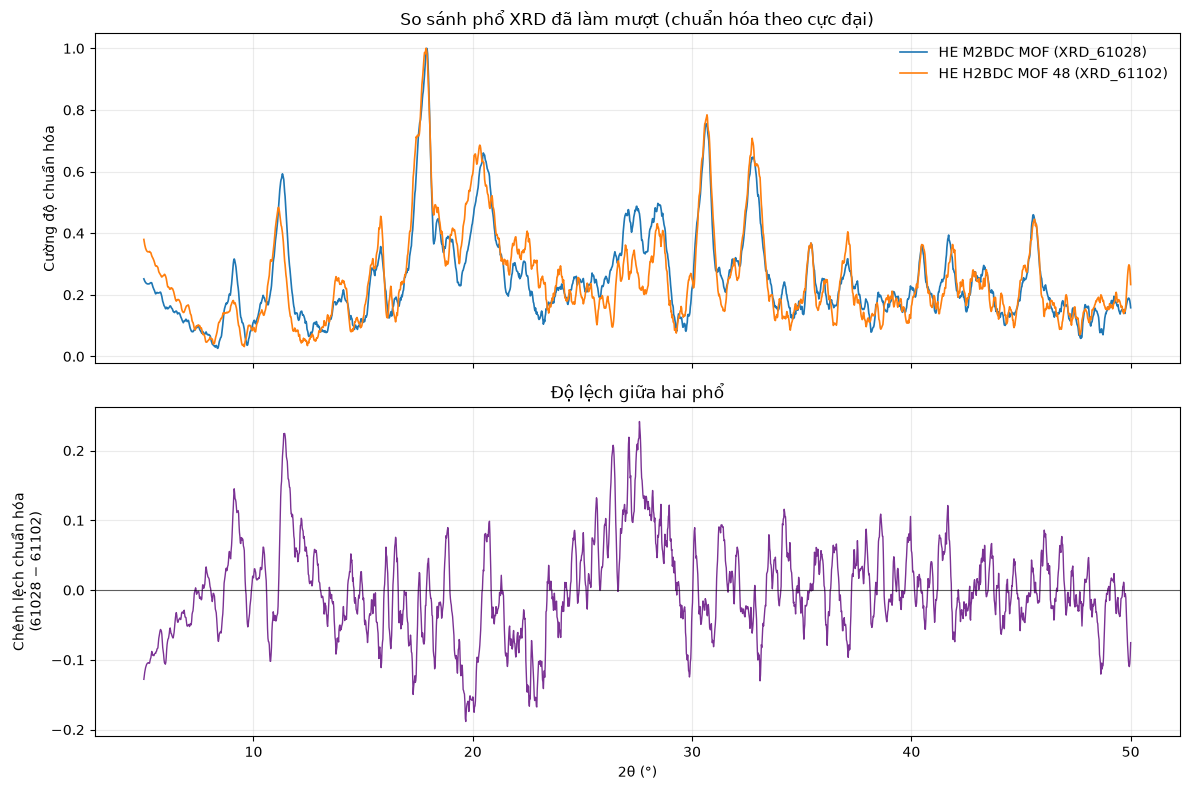

Khoảng 2θ chung: 5.00°–50.00° (2,251 điểm)
Tương quan Pearson giữa hai phổ chuẩn hóa: 0.9042
RMSE của cường độ chuẩn hóa: 0.0668
Khoảng 2θ chung: 5.00°–50.00° (2,251 điểm)
Tương quan Pearson (r): 0.9042
Độ tương đồng Cosine:  0.9686
RMSE chuẩn hóa:        0.0690


In [32]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

_here = Path.cwd().resolve()
search_roots = [_here, *_here.parents]
project_root = next(
    (
        candidate
        for root in search_roots
        for candidate in (root, root / "projects")
        if all((candidate / sample_id / "processed").is_dir() for sample_id in ("XRD_61028", "XRD_61102"))
    ),
    None,
)
if project_root is None:
    raise FileNotFoundError("Không tìm thấy thư mục dự án chứa cả XRD_61028 và XRD_61102")

comparison_files = {
    "HE M2BDC MOF (XRD_61028)": project_root / "XRD_61028" / "processed" / "HE_M2BDC_MOF_smoothed.xy",
    "HE H2BDC MOF 48 (XRD_61102)": project_root / "XRD_61102" / "processed" / "HE_H2BDC_MOF_48_smoothed.xy",
}
comparison_data = {}
for sample_name, file_path in comparison_files.items():
    if not file_path.is_file():
        raise FileNotFoundError(f"Không tìm thấy output cell 6 cho {sample_name}: {file_path}")
    sample_data = pd.read_csv(
        file_path,
        sep=r"\s+",
        header=None,
        names=["two_theta", "intensity"],
    )
    sample_data = sample_data.apply(pd.to_numeric, errors="coerce").dropna()
    sample_data = sample_data.sort_values("two_theta").reset_index(drop=True)
    if sample_data.empty or sample_data["two_theta"].duplicated().any():
        raise ValueError(f"Dữ liệu 2θ không hợp lệ trong {file_path}")
    comparison_data[sample_name] = sample_data

first_name, second_name = comparison_data
first_data = comparison_data[first_name]
second_data = comparison_data[second_name]
common_min = max(first_data["two_theta"].min(), second_data["two_theta"].min())
common_max = min(first_data["two_theta"].max(), second_data["two_theta"].max())
first_common = first_data.loc[first_data["two_theta"].between(common_min, common_max)]
comparison_theta = first_common["two_theta"].to_numpy(dtype=float)
if len(comparison_theta) == 0:
    raise ValueError("Hai phổ không có khoảng 2θ chung để so sánh")

first_intensity = first_common["intensity"].to_numpy(dtype=float)
second_intensity = np.interp(
    comparison_theta,
    second_data["two_theta"].to_numpy(dtype=float),
    second_data["intensity"].to_numpy(dtype=float),
)
first_scale = first_intensity.max()
second_scale = second_intensity.max()
if first_scale <= 0 or second_scale <= 0:
    raise ValueError("Không thể chuẩn hóa phổ vì cường độ cực đại phải lớn hơn 0")
first_normalized = first_intensity / first_scale
second_normalized = second_intensity / second_scale
intensity_difference = first_normalized - second_normalized

fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
axes[0].plot(comparison_theta, first_normalized, label=first_name, linewidth=1.2)
axes[0].plot(comparison_theta, second_normalized, label=second_name, linewidth=1.2)
axes[0].set_ylabel("Cường độ chuẩn hóa")
axes[0].set_title("So sánh phổ XRD đã làm mượt (chuẩn hóa theo cực đại)")
axes[0].legend(frameon=False)
axes[0].grid(True, alpha=0.25)

axes[1].plot(comparison_theta, intensity_difference, color="#7b3294", linewidth=1.0)
axes[1].axhline(0, color="black", linewidth=0.8, alpha=0.6)
axes[1].set_xlabel("2θ (°)")
axes[1].set_ylabel("Chênh lệch chuẩn hóa\n(61028 − 61102)")
axes[1].set_title("Độ lệch giữa hai phổ")
axes[1].grid(True, alpha=0.25)
fig.tight_layout()
plt.show()

correlation = np.corrcoef(first_normalized, second_normalized)[0, 1]
rmse = np.sqrt(np.mean(intensity_difference ** 2))
print(f"Khoảng 2θ chung: {common_min:.2f}°–{common_max:.2f}° ({len(comparison_theta):,} điểm)")
print(f"Tương quan Pearson giữa hai phổ chuẩn hóa: {correlation:.4f}")
print(f"RMSE của cường độ chuẩn hóa: {rmse:.4f}")

# 1. Nội suy cả hai phổ về lưới 2theta đều đặn (bước 0.02°)
step = 0.02
comparison_theta = np.arange(common_min, common_max + step / 2, step)
first_intensity = np.interp(comparison_theta, first_data["two_theta"].to_numpy(float), first_data["intensity"].to_numpy(float))
second_intensity = np.interp(comparison_theta, second_data["two_theta"].to_numpy(float), second_data["intensity"].to_numpy(float))

# 2. Chuẩn hóa Min-Max (đưa đáy về 0 và đỉnh về 1) để giảm bớt ảnh hưởng của nền cao
first_normalized = (first_intensity - first_intensity.min()) / (first_intensity.max() - first_intensity.min())
second_normalized = (second_intensity - second_intensity.min()) / (second_intensity.max() - second_intensity.min())
intensity_difference = first_normalized - second_normalized

# 3. Tính các chỉ số đánh giá
correlation = np.corrcoef(first_normalized, second_normalized)[0, 1]
cosine_sim = np.dot(first_normalized, second_normalized) / (np.linalg.norm(first_normalized) * np.linalg.norm(second_normalized))
rmse = np.sqrt(np.mean(intensity_difference ** 2))

print(f"Khoảng 2θ chung: {common_min:.2f}°–{common_max:.2f}° ({len(comparison_theta):,} điểm)")
print(f"Tương quan Pearson (r): {correlation:.4f}")
print(f"Độ tương đồng Cosine:  {cosine_sim:.4f}")
print(f"RMSE chuẩn hóa:        {rmse:.4f}")

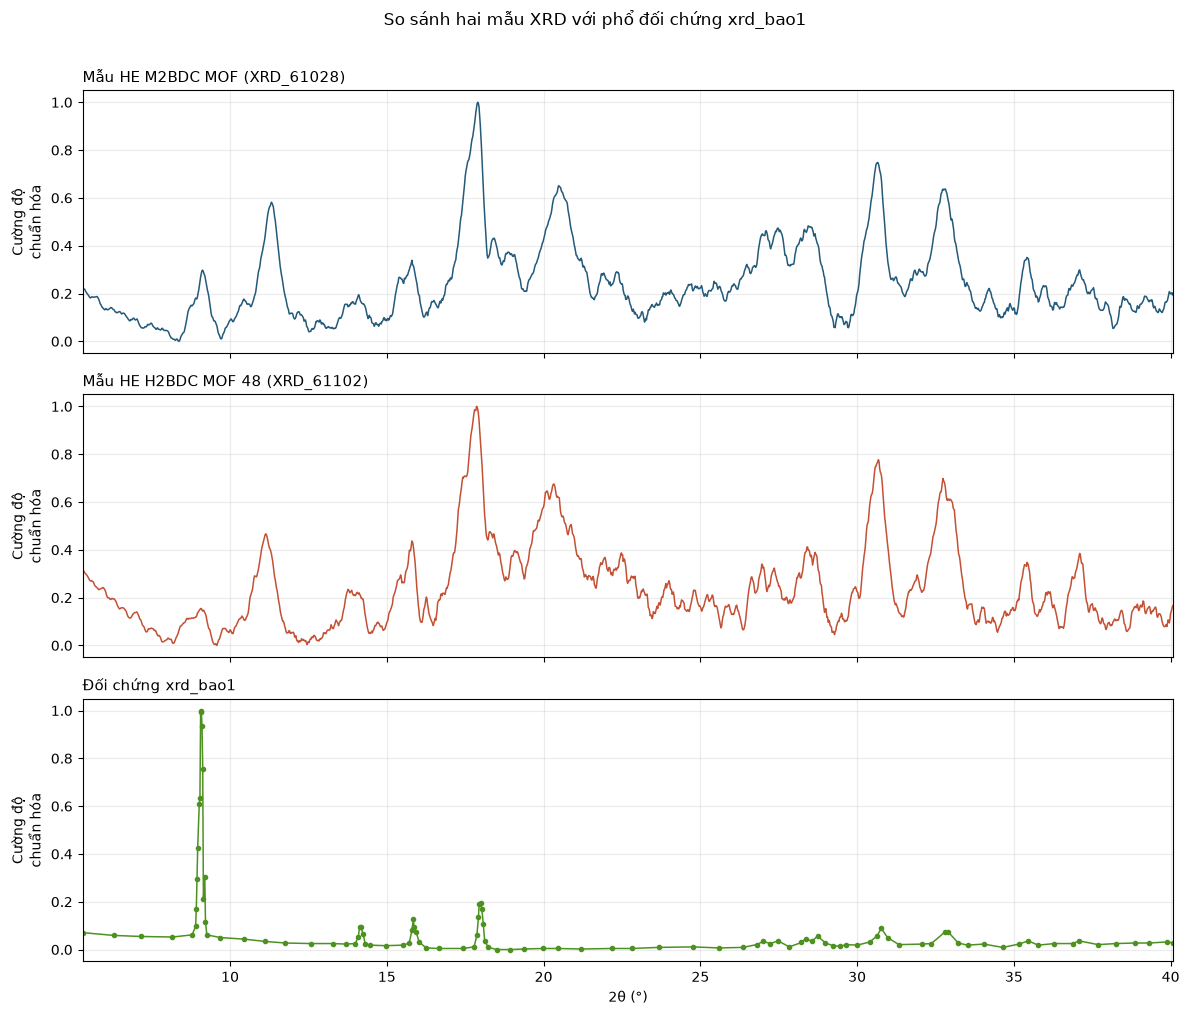

Khoảng 2θ chung của ba phổ: 5.29°–40.08°


In [34]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

_here = Path.cwd().resolve()
project_roots = [_here, *_here.parents]
project_root = next(
    (
        candidate
        for root in project_roots
        for candidate in (root, root / "projects")
        if all((candidate / sample_id / "processed").is_dir() for sample_id in ("XRD_61028", "XRD_61102"))
    ),
    None,
)
if project_root is None:
    raise FileNotFoundError("Không tìm thấy thư mục chứa cả XRD_61028 và XRD_61102")

spectrum_files = [
    (
        "Mẫu HE M2BDC MOF (XRD_61028)",
        project_root / "XRD_61028" / "processed" / "HE_M2BDC_MOF_smoothed.xy",
    ),
    (
        "Mẫu HE H2BDC MOF 48 (XRD_61102)",
        project_root / "XRD_61102" / "processed" / "HE_H2BDC_MOF_48_smoothed.xy",
    ),
    ("Đối chứng xrd_bao1", project_root / "XRD_61028" / "raw" / "xrd_bao1.txt"),
]

spectra = []
for label, file_path in spectrum_files:
    if not file_path.is_file():
        raise FileNotFoundError(f"Không tìm thấy phổ {label}: {file_path}")
    spectrum = pd.read_csv(
        file_path,
        sep=r"\s+",
        header=None,
        names=["two_theta", "intensity"],
    )
    spectrum = spectrum.apply(pd.to_numeric, errors="coerce").dropna()
    spectrum = spectrum[np.isfinite(spectrum["two_theta"]) & np.isfinite(spectrum["intensity"])]
    spectrum = (
        spectrum.groupby("two_theta", as_index=False)["intensity"]
        .mean()
        .sort_values("two_theta")
        .reset_index(drop=True)
    )
    if len(spectrum) < 2:
        raise ValueError(f"Phổ không đủ điểm hợp lệ để vẽ: {file_path}")
    spectra.append((label, spectrum))

common_min = max(spectrum["two_theta"].min() for _, spectrum in spectra)
common_max = min(spectrum["two_theta"].max() for _, spectrum in spectra)
if common_min >= common_max:
    raise ValueError("Ba phổ không có khoảng 2θ chung để so sánh")

fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)
colors = ["#245a7a", "#c45135", "#4d9221"]
for ax, (label, spectrum), color in zip(axes, spectra, colors):
    visible = spectrum.loc[spectrum["two_theta"].between(common_min, common_max)]
    intensity = visible["intensity"].to_numpy(dtype=float)
    intensity_range = np.ptp(intensity)
    if len(visible) < 2 or intensity_range <= 0:
        raise ValueError(f"Phổ không có biến thiên cường độ trong khoảng chung: {label}")
    normalized = (intensity - intensity.min()) / intensity_range
    if "xrd_bao1" in label:
        ax.plot(visible["two_theta"], normalized, color=color, linewidth=1.1, marker="o", markersize=3)
    else:
        ax.plot(visible["two_theta"], normalized, color=color, linewidth=1.1)
    ax.set_title(label, loc="left", fontsize=11)
    ax.set_ylabel("Cường độ\nchuẩn hóa")
    ax.set_ylim(-0.05, 1.05)
    ax.grid(True, alpha=0.25)

axes[-1].set_xlabel("2θ (°)")
axes[-1].set_xlim(common_min, common_max)
fig.suptitle("So sánh hai mẫu XRD với phổ đối chứng xrd_bao1", y=1.01)
fig.tight_layout()
plt.show()
print(f"Khoảng 2θ chung của ba phổ: {common_min:.2f}°–{common_max:.2f}°")